In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ast

In [2]:
df = pd.read_csv('../data/skincare_products_clean.csv')

df['price_num'] = df['price'].astype(str).str.replace('£', '', regex=False).str.replace(',', '', regex=False)
df['price_num'] = pd.to_numeric(df['price_num'], errors='coerce')

df['ingred_list'] = df['clean_ingreds'].apply(ast.literal_eval)
df['ingred_count'] = df['ingred_list'].apply(len)

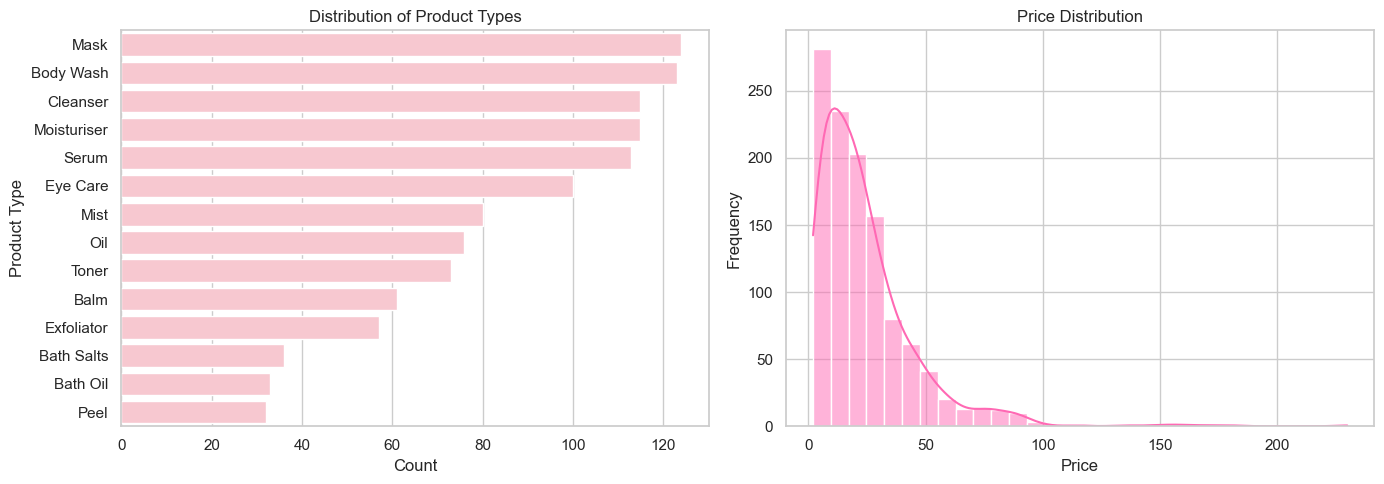

In [3]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(
    data=df,
    y='product_type',
    order=df['product_type'].value_counts().index,
    color='pink',
    ax=axes[0]
)
axes[0].set_title('Distribution of Product Types')
axes[0].set_xlabel('Count')
axes[0].set_ylabel('Product Type')

sns.histplot(
    data=df,
    x='price_num',
    bins=30,
    color='hotpink',
    kde=True,
    ax=axes[1]
)
axes[1].set_title('Price Distribution')
axes[1].set_xlabel('Price')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()